In [49]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# Récupération et nettoyage des données

## Téléchargement des données quotidiennes du S&P500

Dates : 01/01/2018 $\to$ 31/12/2023

In [50]:
ticker = "^GSPC"
df: pd.DataFrame = yf.download(ticker, start="2018-01-01", end="2023-12-31")
df.columns = df.columns.droplevel("Ticker")

[*********************100%***********************]  1 of 1 completed


## Calcul du *log return*

In [62]:
df_returns = (
    pd.DataFrame({"Price" : df["Close"]})
    .reset_index(drop=False)
    .dropna()
)

df_returns["Log_Return"] = np.log(df_returns["Price"] / df_returns["Price"].shift(1))

df_returns = df_returns.dropna()

In [65]:
df_returns

,Date,Price,Log_Return
1,2018-01-03,2713.060059,0.006378
2,2018-01-04,2723.989990,0.004021
3,2018-01-05,2743.149902,0.007009
4,2018-01-08,2747.709961,0.001661
5,2018-01-09,2751.290039,0.001302
...,...,...,...
1504,2023-12-22,4754.629883,0.001659
1505,2023-12-26,4774.750000,0.004223
1506,2023-12-27,4781.580078,0.001429
1507,2023-12-28,4783.350098,0.000370


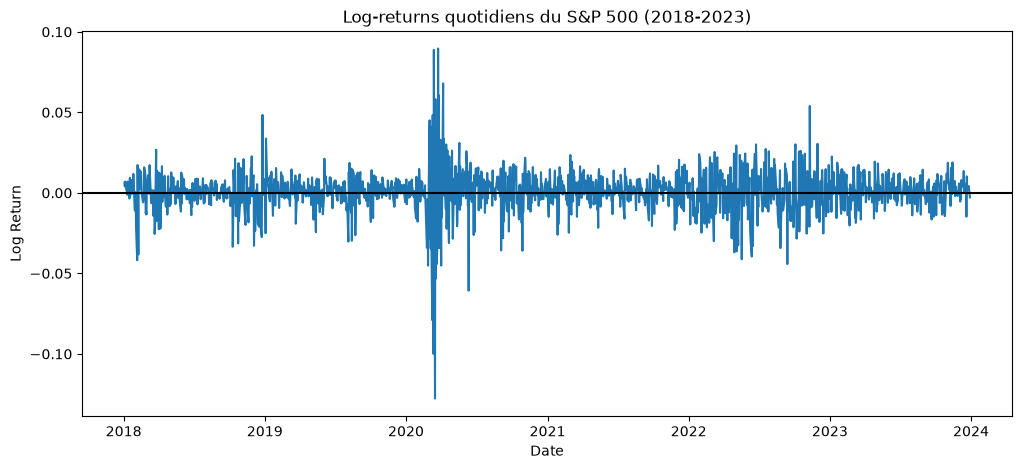

In [69]:
fig, ax = plt.subplots()

fig.set_size_inches(12, 5)
ax.plot(df_returns["Date"], df_returns["Log_Return"], label="Log Returns")
ax.axhline(0, color="black")
ax.set_title("Log-returns quotidiens du S&P 500 (2018-2023)")
ax.set_xlabel("Date")
ax.set_ylabel("Log Return")
plt.show()

## Visualisation de la volatilité

## Nettoyage